# Resultados do modelo de chamados por bairro (Grupo 17)

Análise complementar com dados reais; unidade bairro × mês e alvo `chamados_mes_seguinte`.
Os hiperparâmetros e a escolha já estão registrados em `../models/metadados.json`.
Este notebook reconstrói os sete candidatos com esses parâmetros, mede ajuste/validação/teste
e produz diagnósticos sem alterar os modelos de produção ou registrar um novo treino no MLflow.

Execute a partir desta pasta com as dependências da central, `matplotlib` e Jupyter instalados.
As curvas de CV mostram os cinco folds do treino histórico identificado abaixo; não são uma nova
busca de hiperparâmetros. O teste serve para avaliação final, não para escolher outro modelo.

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.insert(0, str(Path("../src").resolve()))
import treinar as T

PALETA = {"primaria": "#2E6F8E", "secundaria": "#6C757D", "alerta": "#C1502E"}
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.alpha": 0.25, "font.size": 10, "figure.dpi": 110})
meta = json.loads(Path("../models/metadados.json").read_text(encoding="utf-8"))
print("Treino histórico:", meta["treinado_em"])
print("Modelo escolhido anteriormente:", meta["modelo"])
print("Critério:", meta["criterio_selecao"])

df = T.carregar()
treino = df[df["conjunto"] == "treino"].copy()
teste_base = df[df["conjunto"] == "teste"].copy()
meses_validacao = sorted(treino["mes_do_alvo"].unique())[-12:]
ajuste = treino[~treino["mes_do_alvo"].isin(meses_validacao)].copy()
validacao = treino[treino["mes_do_alvo"].isin(meses_validacao)].copy()
particoes = {"ajuste": ajuste, "val": validacao, "teste": teste_base}
display(pd.DataFrame([{"partição": nome, "linhas": len(base), "alvo_início": base["mes_do_alvo"].min(),
                       "alvo_fim": base["mes_do_alvo"].max()} for nome, base in particoes.items()]))
assert ajuste["mes_do_alvo"].max() < validacao["mes_do_alvo"].min()
assert validacao["mes_do_alvo"].max() < teste_base["mes_do_alvo"].min()

C:\Users\claud\Documents\Codex\2026-11-27\eu-preciso-que-esse-chat-seja\work\t18-venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Treino histórico: 2026-11-26T11:17:33
Modelo escolhido anteriormente: poisson_glm
Critério: menor val_mae (alvos 2024) apos tuning via TimeSeriesSplit


,partição,linhas,alvo_início,alvo_fim
0,ajuste,1880,2022-05,2023-12
1,val,1128,2024-01,2024-12
2,teste,1128,2025-01,2025-12


## 1. Métricas dos sete candidatos

Para ajuste e validação, cada modelo aprende no ajuste. Para o teste, é retreinado em todo o treino
(ajuste + validação), reproduzindo `treinar.py`. Logo, a comparação dos três períodos também envolve
mais dados no modelo usado no teste; a diferença não mede apenas overfitting.
Precisão top 10% é a média mensal da interseção entre os nove bairros previstos e os nove reais,
tanto por contagem quanto por taxa. MAE/RMSE menores e R²/precisão maiores são melhores.

Os parâmetros foram otimizados historicamente por CV no treino completo, que inclui 2024.
A validação de 2024 orientou a seleção, mas não é independente dessa busca; o teste de 2025 permanece
fora da busca. Uma avaliação com validação aninhada seria uma melhoria futura.

In [2]:
resultados, previsoes, modelos_teste = {}, {}, {}
for nome in meta["metricas"]:
    params = meta["parametros_por_modelo"][nome]
    candidato = T.construir_modelo(nome, params)
    candidato.fit(ajuste[T.FEATURES], ajuste[T.ALVO])
    medidas = {}
    for prefixo, base in (("ajuste", ajuste), ("val", validacao)):
        previsto = candidato.predict(base[T.FEATURES])
        medidas.update(T.medir(base, previsto, prefixo))
        previsoes[(nome, prefixo)] = previsto
    candidato.fit(treino[T.FEATURES], treino[T.ALVO])
    previsto = candidato.predict(teste_base[T.FEATURES])
    medidas.update(T.medir(teste_base, previsto, "teste"))
    previsoes[(nome, "teste")] = previsto
    modelos_teste[nome] = candidato
    resultados[nome] = medidas

metricas = pd.DataFrame(resultados).T
ordem = metricas.sort_values("val_mae").index
colunas = [f"{periodo}_{metrica}" for periodo in ("ajuste", "val", "teste")
           for metrica in ("mae", "rmse", "r2", "precisao_top10", "precisao_top10_taxa")]
display(metricas.loc[ordem, colunas].round(3))
# Metadados foram arredondados a quatro casas; detectar divergências na reprodução.
referencia = pd.DataFrame(meta["metricas"]).T[colunas].astype(float)
delta = (metricas[colunas] - referencia).abs()
print("Maior diferença absoluta frente ao registro histórico:", delta.max().max())
assert np.isfinite(metricas[colunas].to_numpy()).all()
assert delta.max().max() < 0.001, "Métricas divergiram; revisar ambiente/dados antes de interpretar."
modelo = modelos_teste[meta["modelo"]]
teste = teste_base.assign(previsto=previsoes[(meta["modelo"], "teste")])
mensal = teste.groupby("mes_do_alvo")[[T.ALVO, "previsto", "media_movel_3m"]].sum()

,ajuste_mae,ajuste_rmse,ajuste_r2,ajuste_precisao_top10,ajuste_precisao_top10_taxa,val_mae,val_rmse,val_r2,val_precisao_top10,val_precisao_top10_taxa,teste_mae,teste_rmse,teste_r2,teste_precisao_top10,teste_precisao_top10_taxa
poisson_glm,7.605,12.282,0.803,0.750,0.411,8.667,14.510,0.836,0.769,0.583,8.073,12.633,0.893,0.796,0.574
regra_media_movel_3m,9.533,15.644,0.681,0.744,0.378,8.927,14.538,0.836,0.778,0.556,8.662,13.648,0.875,0.750,0.574
baseline_linear,7.743,12.072,0.810,0.750,0.389,9.135,14.846,0.829,0.778,0.537,8.271,12.295,0.899,0.815,0.509
random_forest,5.073,7.564,0.925,0.817,0.567,9.327,16.313,0.793,0.806,0.565,7.825,12.147,0.901,0.796,0.565
hist_gb_poisson,5.147,7.510,0.926,0.822,0.561,9.508,16.943,0.777,0.796,0.574,7.890,12.227,0.900,0.815,0.546
regra_persistencia,8.873,14.318,0.732,0.722,0.383,9.551,15.649,0.810,0.731,0.528,9.207,13.853,0.872,0.806,0.481
gradient_boosting,6.383,9.261,0.888,0.789,0.439,9.603,16.390,0.791,0.787,0.546,8.258,13.017,0.887,0.759,0.546


Maior diferença absoluta frente ao registro histórico: 4.944634389669744e-05


### Erro (MAE) de cada candidato, na validação e no teste

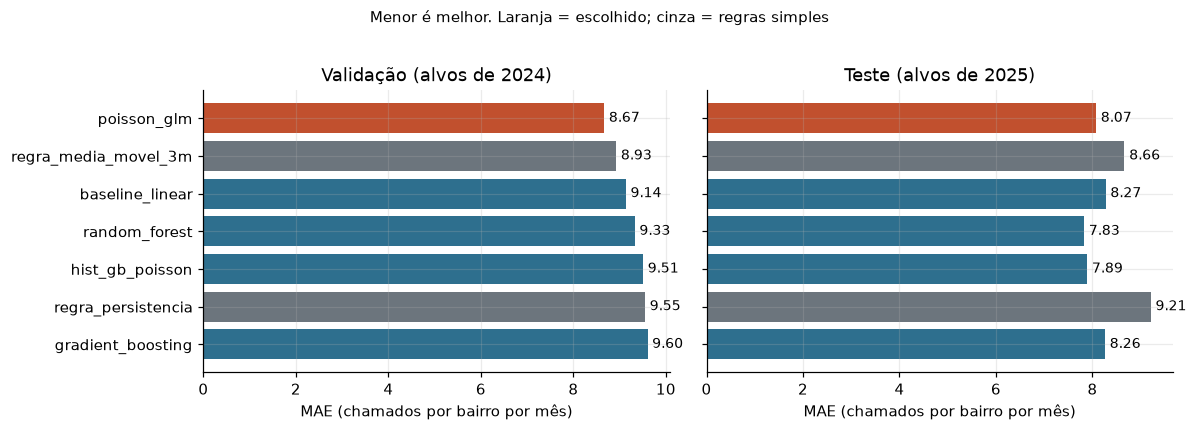

In [3]:
ordem = metricas.sort_values("val_mae").index
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for ax, coluna, titulo in zip(axes, ["val_mae", "teste_mae"], ["Validação (alvos de 2024)", "Teste (alvos de 2025)"]):
    valores = metricas.loc[ordem, coluna]
    cores = [PALETA["alerta"] if n == meta["modelo"] else PALETA["secundaria"] if n.startswith("regra_") else PALETA["primaria"] for n in ordem]
    ax.barh(ordem[::-1], valores[::-1], color=cores[::-1])
    for y, v in enumerate(valores[::-1]):
        ax.text(v + 0.1, y, f"{v:.2f}", va="center", fontsize=9)
    ax.set_title(titulo)
    ax.set_xlabel("MAE (chamados por bairro por mês)")
fig.suptitle("Menor é melhor. Laranja = escolhido; cinza = regras simples", fontsize=10, y=1.02)
plt.tight_layout()
plt.show()

**Leitura:** o `poisson_glm` é o único candidato de ML abaixo da melhor regra
(`media_movel_3m`) na validação recente. No teste, `random_forest` e `hist_gb_poisson` têm MAE menor
que o GLM; isso não altera a seleção feita pela validação. A inversão de ordem entre períodos
reforça a importância de avaliar estabilidade e manter o teste fora da escolha.

## 2. Ajuste, validação e estabilidade temporal

O primeiro gráfico mostra a MAE nos três períodos com os protocolos descritos acima.
Os gráficos seguintes usam os cinco folds de `TimeSeriesSplit`, agrupados por mês do alvo,
armazenados em `metadados.json`. As barras de erro representam desvio padrão entre folds, **não**
intervalos de confiança. CV foi usada na busca: seus resultados também não são uma avaliação externa.

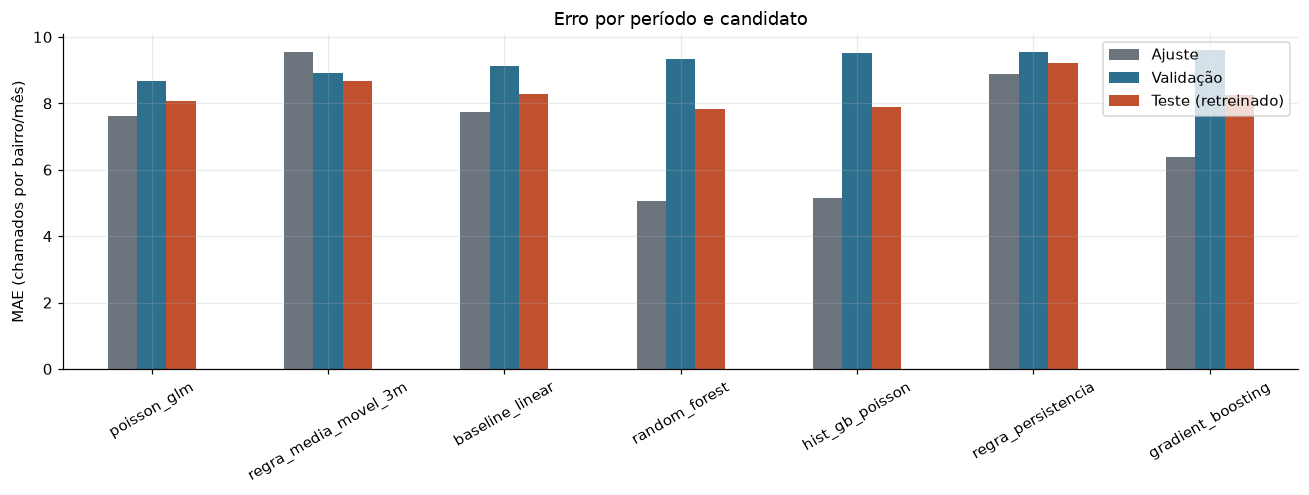

,modelo,fold,val_inicio,val_fim,cv_ajuste_mae,cv_mae,cv_gap_mae
0,regra_persistencia,1,2022-12,2023-04,8.808,6.979,-1.830
1,regra_persistencia,2,2023-05,2023-09,8.046,11.800,3.754
2,regra_persistencia,3,2023-10,2024-02,9.150,7.996,-1.154
3,regra_persistencia,4,2024-03,2024-07,8.888,10.487,1.599
4,regra_persistencia,5,2024-08,2024-12,9.184,8.819,-0.365
5,regra_media_movel_3m,1,2022-12,2023-04,8.892,6.727,-2.165
6,regra_media_movel_3m,2,2023-05,2023-09,7.990,12.094,4.104
7,regra_media_movel_3m,3,2023-10,2024-02,9.197,11.105,1.908
8,regra_media_movel_3m,4,2024-03,2024-07,9.631,8.426,-1.205
9,regra_media_movel_3m,5,2024-08,2024-12,9.407,8.758,-0.649


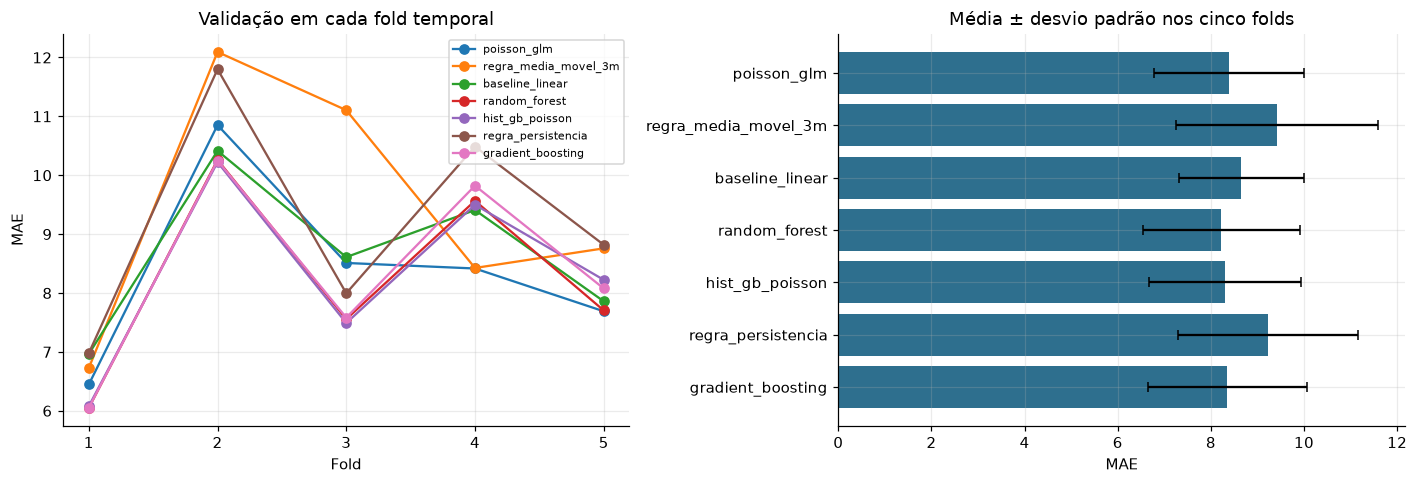

In [4]:
comparacao = metricas.loc[ordem, ["ajuste_mae", "val_mae", "teste_mae"]]
comparacao.columns = ["Ajuste", "Validação", "Teste (retreinado)"]
ax = comparacao.plot.bar(figsize=(12, 4.6), color=[PALETA["secundaria"], PALETA["primaria"], PALETA["alerta"]])
ax.set_ylabel("MAE (chamados por bairro/mês)")
ax.set_title("Erro por período e candidato")
ax.tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.show()

folds = pd.concat([pd.DataFrame(linhas).assign(modelo=nome) for nome, linhas in meta["cv_folds"].items()], ignore_index=True)
assert folds.groupby("modelo").size().eq(5).all()
display(folds[["modelo", "fold", "val_inicio", "val_fim", "cv_ajuste_mae", "cv_mae", "cv_gap_mae"]].round(3))
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for nome in ordem:
    f = folds[folds["modelo"] == nome].sort_values("fold")
    axes[0].plot(f["fold"], f["cv_mae"], marker="o", label=nome)
resumo_cv = folds.groupby("modelo")["cv_mae"].agg(["mean", "std"]).loc[ordem]
axes[1].barh(ordem[::-1], resumo_cv["mean"][::-1], xerr=resumo_cv["std"][::-1], capsize=3, color=PALETA["primaria"])
axes[0].set(title="Validação em cada fold temporal", xlabel="Fold", ylabel="MAE")
axes[0].set_xticks(range(1, 6))
axes[0].legend(fontsize=7)
axes[1].set(title="Média ± desvio padrão nos cinco folds", xlabel="MAE")
plt.tight_layout()
plt.show()

**Leitura:** erro baixo no ajuste com aumento na validação indica possível sobreajuste.
As árvores apresentam gaps maiores que o GLM nos registros históricos; a variação entre folds mostra
dependência do período. R² alto no teste pode coexistir com falhas no ranking de bairros e com erros
grandes em observações específicas. Avalie as métricas e os gráficos em conjunto.

## 3. Real × previsto por bairro/mês (teste)

Cada ponto é uma observação do teste, não o total mensal. A reta tracejada representa previsão perfeita.
Os modelos de teste aprenderam apenas no treino; o modelo de produção salvo aprende em toda a base
e não deve ser usado para medir estes resultados.

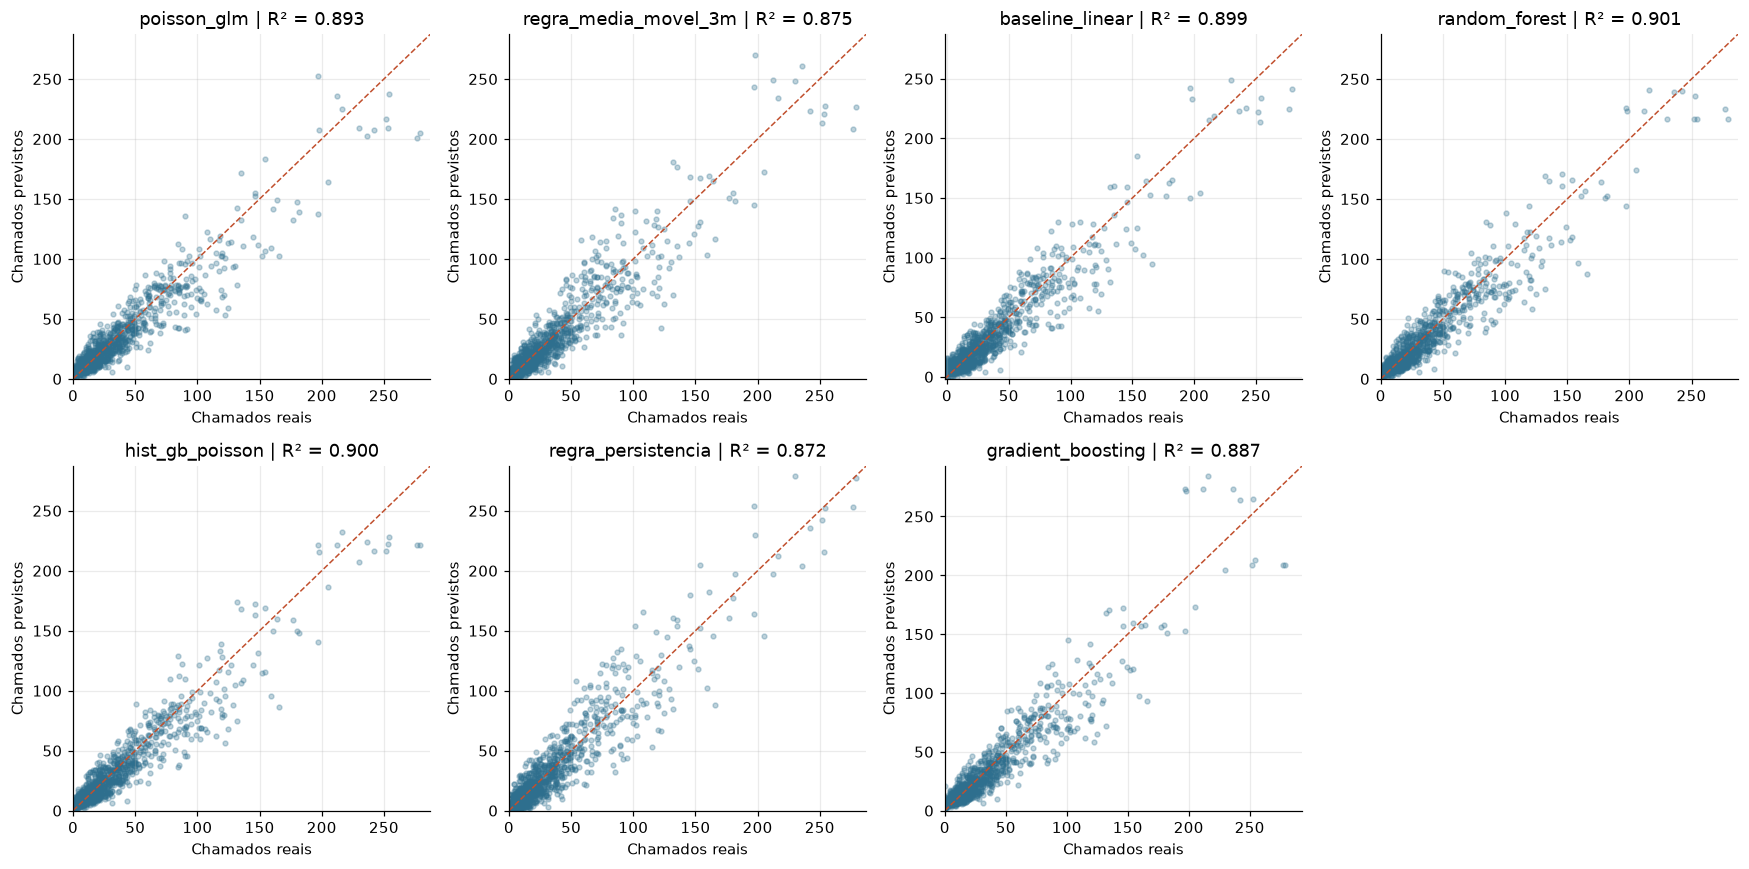

In [5]:
nomes = list(ordem)
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
real = teste_base[T.ALVO].to_numpy()
for ax, nome in zip(axes.flat, nomes):
    previsto = previsoes[(nome, "teste")]
    limites = [min(0, real.min(), previsto.min()), max(real.max(), previsto.max()) * 1.03]
    ax.scatter(real, previsto, s=10, alpha=0.3, color=PALETA["primaria"])
    ax.plot(limites, limites, "--", color=PALETA["alerta"], linewidth=1)
    ax.set(xlim=limites, ylim=limites, xlabel="Chamados reais", ylabel="Chamados previstos",
           title=f"{nome} | R² = {metricas.loc[nome, 'teste_r2']:.3f}")
for ax in list(axes.flat)[len(nomes):]:
    ax.set_visible(False)
plt.tight_layout()
plt.show()

## 4. Resíduos: real − previsto (teste)

Resíduo positivo indica subestimação; negativo, superestimação. A referência horizontal é zero.
Tendência, dispersão crescente e caudas longas indicam erros que uma média global esconde.
Os histogramas usam a mesma faixa entre candidatos para permitir comparação.

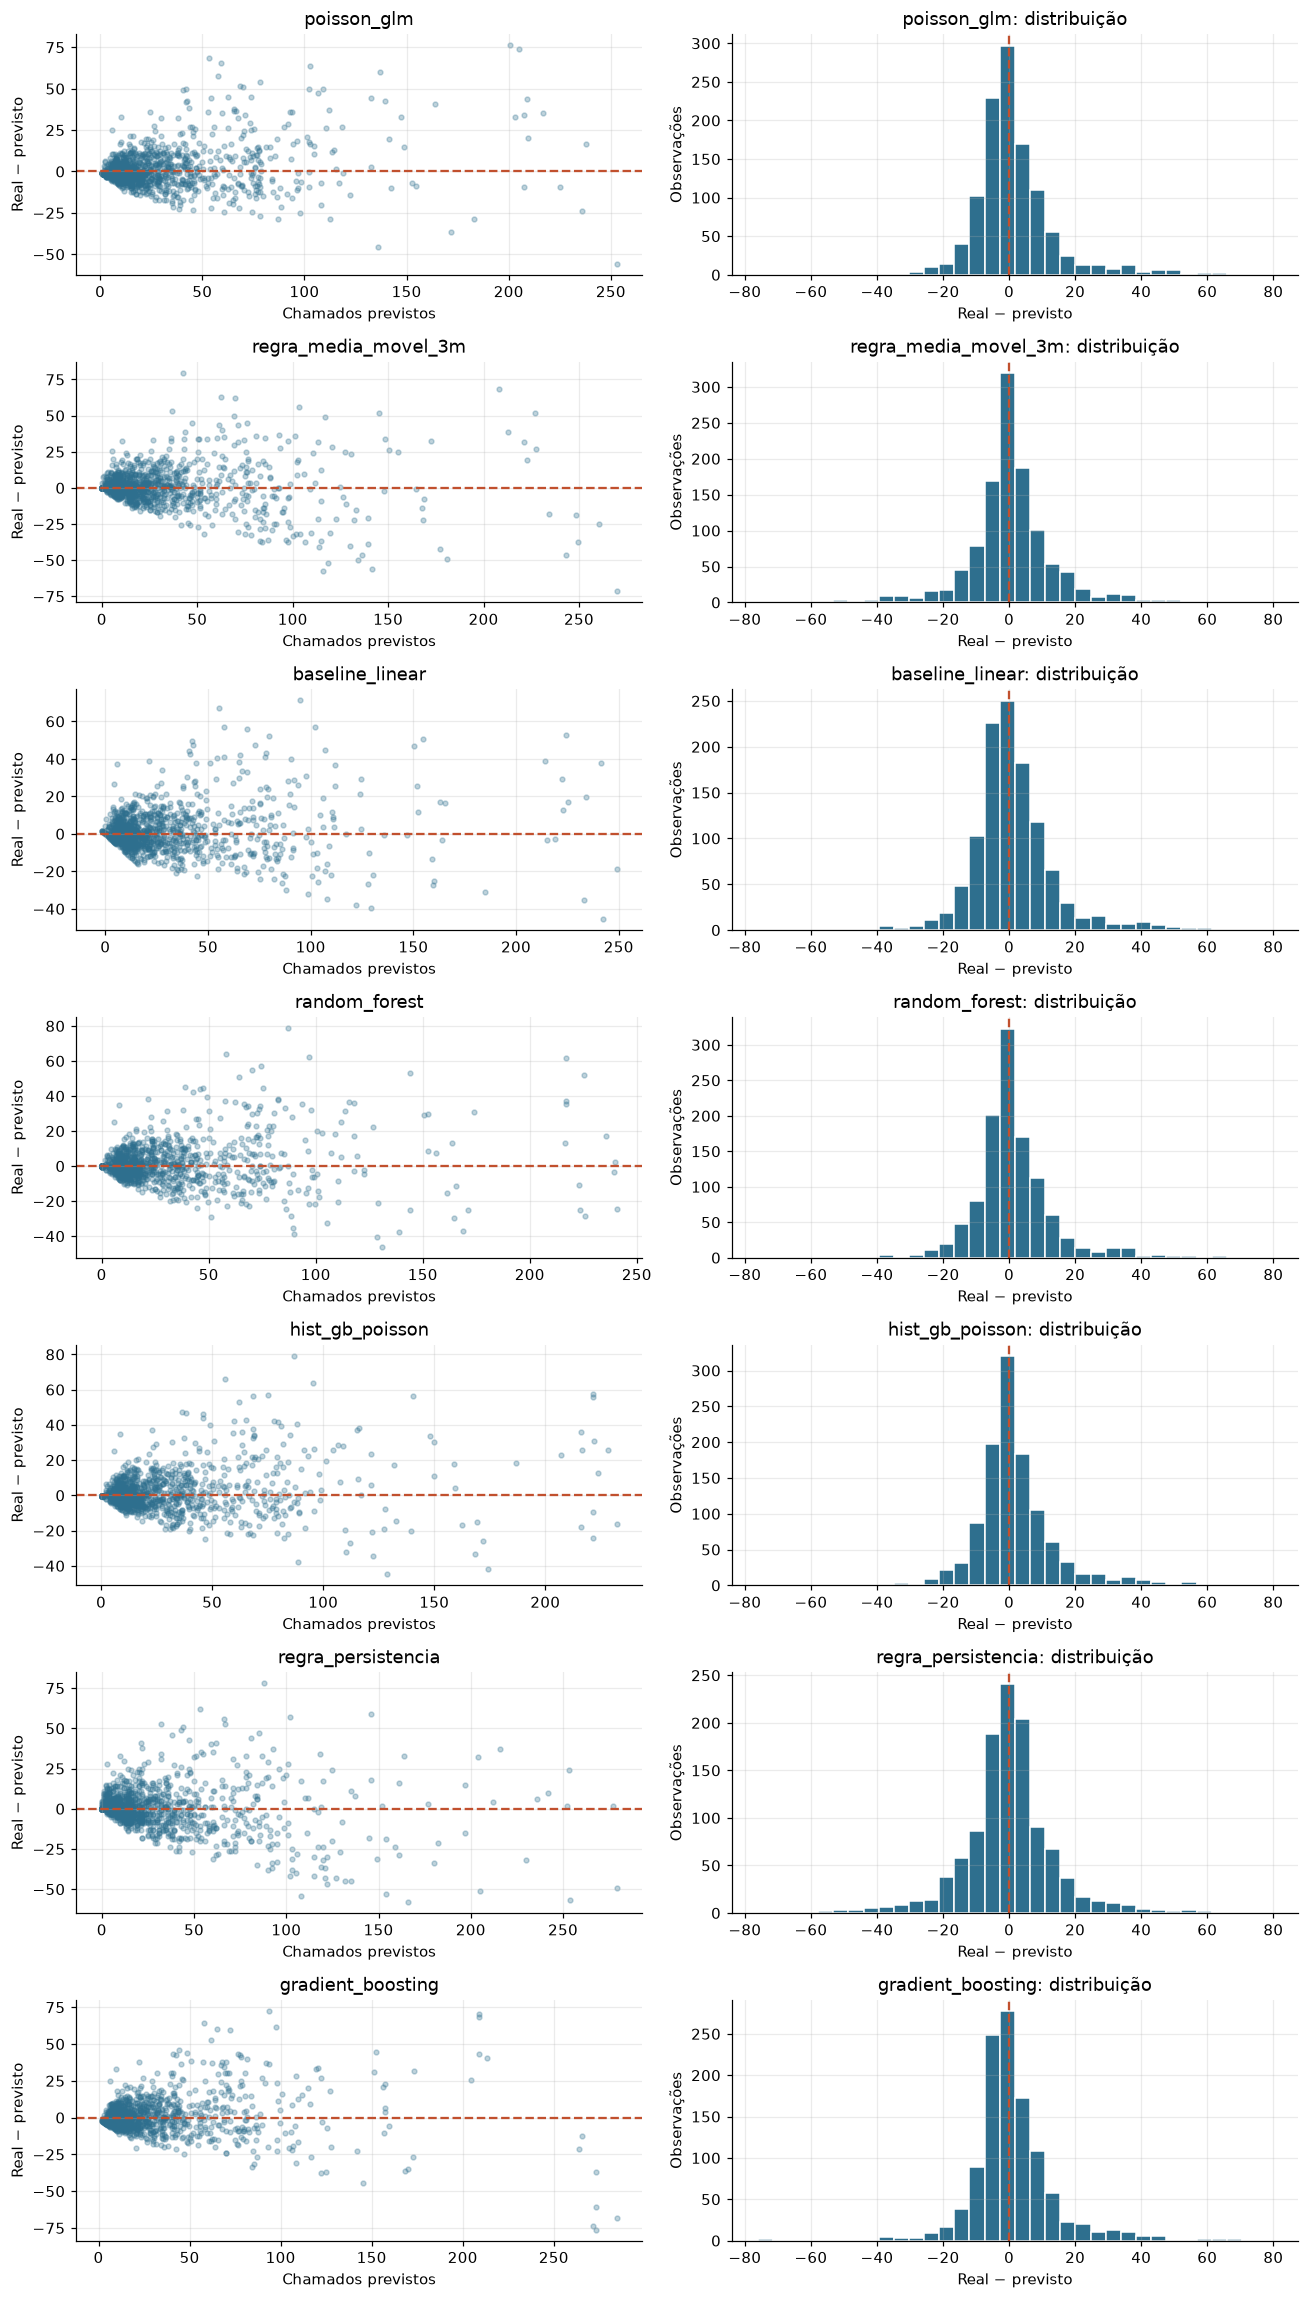

,viés_médio,mediana,p95_erro_absoluto
modelo,,,
poisson_glm,1.564,-0.826,26.804
regra_media_movel_3m,0.770,0.000,32.217
baseline_linear,1.326,-0.113,25.914
random_forest,1.410,-0.082,27.460
hist_gb_poisson,1.835,-0.187,25.715
regra_persistencia,0.078,0.000,31.000
gradient_boosting,1.128,-0.533,28.439


In [6]:
residuos = {nome: real - previsoes[(nome, "teste")] for nome in nomes}
bins = np.linspace(min(r.min() for r in residuos.values()), max(r.max() for r in residuos.values()), 35)
fig, axes = plt.subplots(len(nomes), 2, figsize=(12, 3 * len(nomes)))
resumo_residuos = []
for linha, nome in enumerate(nomes):
    residuo = residuos[nome]
    axes[linha, 0].scatter(previsoes[(nome, "teste")], residuo, s=10, alpha=0.3, color=PALETA["primaria"])
    axes[linha, 0].axhline(0, linestyle="--", color=PALETA["alerta"])
    axes[linha, 0].set(title=nome, xlabel="Chamados previstos", ylabel="Real − previsto")
    axes[linha, 1].hist(residuo, bins=bins, color=PALETA["primaria"], edgecolor="white")
    axes[linha, 1].axvline(0, linestyle="--", color=PALETA["alerta"])
    axes[linha, 1].set(title=f"{nome}: distribuição", xlabel="Real − previsto", ylabel="Observações")
    resumo_residuos.append({"modelo": nome, "viés_médio": residuo.mean(),
                           "mediana": np.median(residuo), "p95_erro_absoluto": np.quantile(abs(residuo), 0.95)})
plt.tight_layout()
plt.show()
display(pd.DataFrame(resumo_residuos).set_index("modelo").round(3))

## 5. Total de chamados por mês no teste: real × previsto

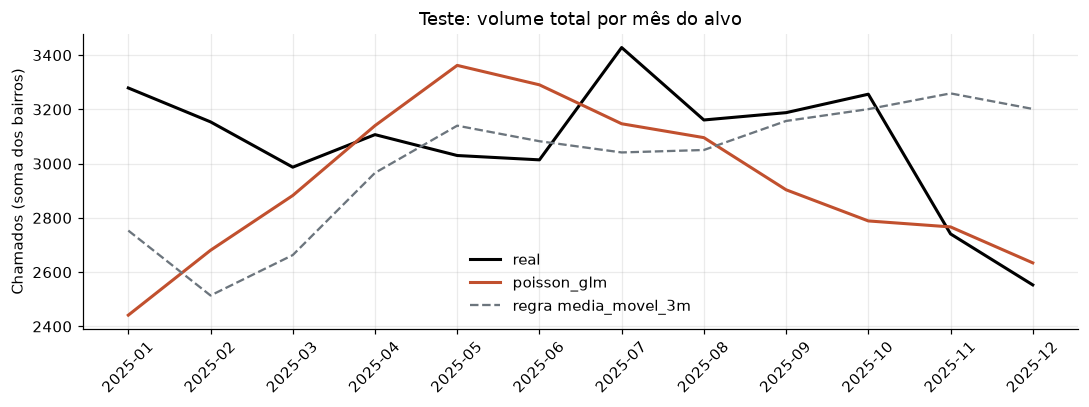

In [7]:
fig, ax = plt.subplots(figsize=(10, 3.8))
ax.plot(mensal.index, mensal[T.ALVO], color="black", linewidth=2, label="real")
ax.plot(mensal.index, mensal["previsto"], color=PALETA["alerta"], linewidth=2, label=meta["modelo"])
ax.plot(mensal.index, mensal["media_movel_3m"], color=PALETA["secundaria"], linestyle="--", label="regra media_movel_3m")
ax.set(ylabel="Chamados (soma dos bairros)", title="Teste: volume total por mês do alvo")
ax.legend(frameon=False)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## 6. O que o modelo usa (coeficientes do GLM de Poisson)

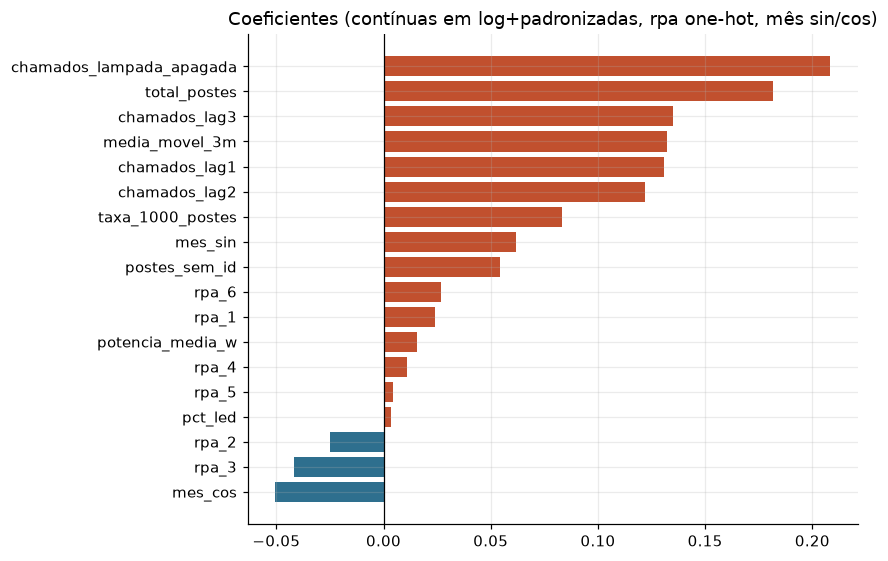

In [8]:
if meta["modelo"] == "poisson_glm":
    nomes = [n.split("__", 1)[-1] for n in modelo[:-1].get_feature_names_out()]
    coef = pd.Series(modelo[-1].coef_, index=nomes).sort_values()
    fig, ax = plt.subplots(figsize=(8, 5.2))
    ax.barh(coef.index, coef.values, color=[PALETA["alerta"] if v > 0 else PALETA["primaria"] for v in coef.values])
    ax.axvline(0, color="black", linewidth=0.8)
    ax.set_title("Coeficientes (contínuas em log+padronizadas, rpa one-hot, mês sin/cos)")
    plt.tight_layout()
    plt.show()
else:
    print("O gráfico de coeficientes só se aplica ao poisson_glm.")

**Leitura:** os coeficientes estão na escala do log da média prevista. As contínuas receberam
log e padronização; RPA tem indicadores one-hot e o mês tem seno/cosseno. Por isso não se deve comparar
diretamente a magnitude de todos os coeficientes como se estivessem na mesma escala.
Lags correlacionados dividem influência; coeficientes não demonstram causalidade.

## 7. Risco por contagem × risco por taxa (por 1.000 postes)

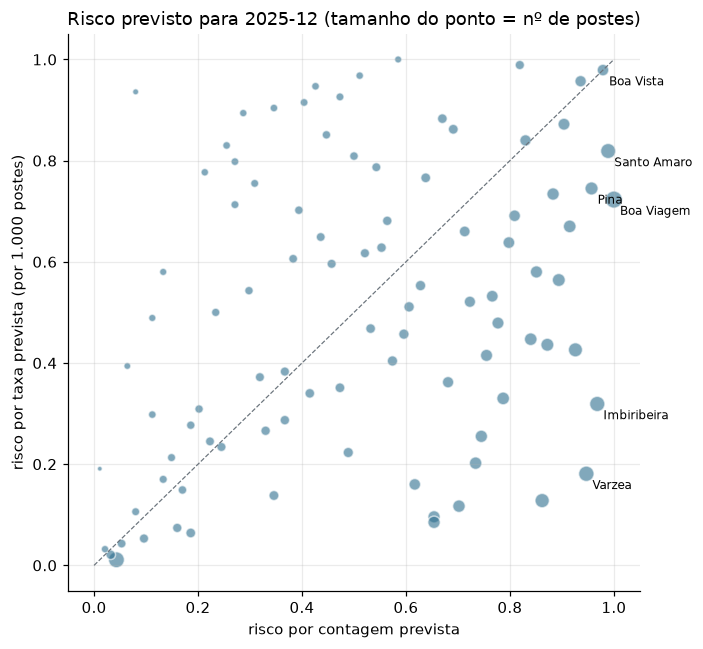

In [9]:
risco = pd.read_csv("../models/risco_por_bairro.csv")
fig, ax = plt.subplots(figsize=(6.5, 6))
ax.scatter(risco["risco_contagem"], risco["risco_taxa"], s=np.sqrt(risco["total_postes"]) * 1.5,
           color=PALETA["primaria"], alpha=0.6, edgecolor="white")
for _, r in risco.nlargest(6, "risco_contagem").iterrows():
    ax.annotate(r["bairro"].title(), (r["risco_contagem"], r["risco_taxa"]), fontsize=8,
                xytext=(4, -10), textcoords="offset points")
ax.plot([0, 1], [0, 1], color=PALETA["secundaria"], linewidth=0.8, linestyle="--")
ax.set_xlabel("risco por contagem prevista")
ax.set_ylabel("risco por taxa prevista (por 1.000 postes)")
ax.set_title(f"Risco previsto para {risco['mes_previsto'].iloc[0]} (tamanho do ponto = nº de postes)")
plt.tight_layout()
plt.show()

**Leitura:** bairros grandes (pontos maiores) ficam à direita no ranking por contagem, mas vários caem
no ranking por taxa (ex.: Várzea e Imbiribeira). Boa Vista e Recife ficam no topo dos dois: muitos chamados
**e** muitos por poste. A escolha de qual ranking vira o risco publicado está em `criterio_risco`, no
`config.json`, e é uma decisão do grupo para explicar no relatório.

## 8. Limitações e interpretação

- O cadastro estático de **2025** é aplicado à série **2022–2025**. A suposição de estabilidade do parque
  pode introduzir *look-ahead* nas features estáticas; o split temporal não corrige essa limitação.
- A precisão por taxa por 1.000 postes é menor que por contagem. O GLM fica em torno de 0,55–0,57
  no top 10% por taxa; consulte o valor exato na tabela executada. A escolha operacional cabe ao grupo.
- O GLM escolhido melhora a MAE, mas não supera necessariamente a persistência no top 10% por contagem.
  Uma melhora no erro médio não garante a melhor lista de manutenção.
- A baseline linear pode prever contagens negativas; esses valores são mantidos nos diagnósticos
  para explicitar sua limitação. Esta análise não usa o modelo retreinado em produção para avaliar o teste.
- CV e validação compartilham períodos no protocolo histórico. A comparação não equivale a validação
  aninhada. Não se alteraram os hiperparâmetros após olhar os gráficos do teste.
- Chamados refletem atendimento e notificação, não o conjunto completo de falhas físicas. Estes
  resultados complementares não medem o desempenho do modelo de falha em 14 dias do notebook 03.